# Phase 1 — มืออยู่ในเฟรมแต่ MediaPipe จับไม่เจอ

**อาการ (จากเพื่อน):** ตอนใช้ webcam มืออยู่ในเฟรมชัดๆ แต่ระบบหามือไม่เจอ

**สมมติฐาน:** MediaPipe Holistic ไม่ได้หามือจากทั้งภาพ แต่หา**ตัว (pose)** ก่อน แล้วใช้**ข้อมือของ pose** ไปครอปหามือ
ถ้ามือขยับเร็ว เบลอ หรือความมั่นใจต่ำกว่า `minHandLandmarksConfidence = 0.5` (`webapp/web/lib/holistic.ts:33`) มือก็จะหายไป

**วิธีทดสอบ:** รัน MediaPipe ตัวเดียวกับเว็บ (`models/mediapipe/holistic_landmarker.task`) กับวิดีโอจริงใน `data_test/` (64 คลิป) ด้วย 4 แบบ

| แบบ | threshold มือ | ปรับแสงแบบ browser |
|---|---|---|
| A_default | 0.5 | ไม่ (= ที่ใช้สร้างข้อมูล train และ `python main.py test`) |
| B_norm | 0.5 | ใช่ (= เว็บตอนนี้) |
| C_norm_hand0.3 | 0.3 | ใช่ |
| D_norm_hand0.1 | 0.1 | ใช่ |
| E_norm_clamped | 0.5 | ใช่ แต่จำกัดความแรง (gamma ≥ 0.75, contrast ≤ 1.3) — รอบ 2 |
| F_up2x | 0.5 | ไม่ + ขยายภาพ 2 เท่าถ้าภาพเล็กกว่า 900 px — รอบ 2 |

**ตัววัด**
- **miss rate** = ในเฟรมที่**ข้อมือของ pose ยกขึ้นมาแล้ว** (กฎเดียวกับ `handsUp` ในเว็บ) **และอยู่ในเฟรมจริง** (ไม่ชิดขอบล่าง y < 0.9) มีกี่ % ที่**ไม่มี landmark มือ**
  (รอบแรกไม่ได้กันขอบล่าง เลยนับมือที่วางพักอยู่ขอบภาพ 7.3 วินาทีใน "พ่อดื่มน้ำ" เป็น "หาย" ไปด้วย)
- **mismatch** = มือที่เจอแต่ไปอยู่ไกลจากข้อมือของ pose (น่าจะเป็นมือหลอก)
- **ผลการแปล** ของ 5 วิดีโอประโยค (`data_test/*.mp4`) เทียบแต่ละแบบ

In [1]:
import sys, json, glob
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
plt.rcParams['font.family'] = ['Tahoma', 'Leelawadee UI', 'DejaVu Sans']; plt.rcParams['figure.dpi'] = 110
pd.set_option('display.width', 180)
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'models' / 'bank.npz').exists())   # works from Main_demo/ or pitty/notebooks/; sys.path.insert(0, str(ROOT))
from modules.mediapipe_pose import load_raw
CACHE = ROOT / 'cache' / 'pitty_hands'
SETTINGS = ['A_default', 'B_norm', 'C_norm_hand0.3', 'D_norm_hand0.1', 'E_norm_clamped', 'F_up2x']
OUT = ROOT / 'result_reporting' / 'pitty'; OUT.mkdir(parents=True, exist_ok=True)

## 1. มือหายกี่ % ตอนที่ข้อมือยกขึ้นมาแล้ว

In [2]:
def hand_stats(raw):
    P, hw = raw['pose'], raw['hw']
    ls, rs = P[:, 11, :2], P[:, 12, :2]
    sw = np.linalg.norm(ls - rs, axis=1); sw[sw == 0] = 0.2
    midY = (ls[:, 1] + rs[:, 1]) / 2
    has_pose = P[:, :, 3].max(1) > 0
    out = {}
    for side, wi, H in (('L', 15, raw['lh']), ('R', 16, raw['rh'])):
        w = P[:, wi]
        up = has_pose & (w[:, 3] > 0.5) & (w[:, 1] < midY + 1.3 * sw) & (w[:, 0] > 0.03) & (w[:, 0] < 0.97) & (w[:, 1] > 0.03) & (w[:, 1] < 0.9)
        found = np.abs(H).sum((1, 2)) > 0
        dist = np.linalg.norm(H[:, 0, :2] - w[:, :2], axis=1) / sw     # hand-model wrist vs pose wrist, in shoulder widths
        out[side] = dict(up=up, found=found, mismatch=found & (dist > 0.6))
    return out

rows = []
for s in SETTINGS:
    for f in sorted((CACHE / s).glob('*.npz')):
        st = hand_stats(load_raw(f))
        grp = 'jack_test (คำเดี่ยว)' if f.stem.startswith('jack__') else 'data_test (ประโยค)'
        up = sum(v['up'].sum() for v in st.values())
        rows.append(dict(setting=s, group=grp, video=f.stem, frames=len(st['L']['up']), up=up,
                         missed=sum((v['up'] & ~v['found']).sum() for v in st.values()),
                         found=sum(v['found'].sum() for v in st.values()), mismatch=sum(v['mismatch'].sum() for v in st.values())))
H = pd.DataFrame(rows)
summ = H.groupby(['group', 'setting'])[['frames', 'up', 'missed', 'found', 'mismatch']].sum()
summ['miss_rate'] = summ.missed / summ.up; summ['mismatch_rate'] = summ.mismatch / summ.found
summ.round(3)

frames    up  missed  found  mismatch  miss_rate  mismatch_rate
group                setting                                                                        
data_test (ประโยค)   A_default         1636  1307     116   1945         1      0.089          0.001
                     B_norm            1636  1309     259   1762         0      0.198          0.000
                     C_norm_hand0.3    1636  1309     259   1762         0      0.198          0.000
                     D_norm_hand0.1    1636  1309     259   1762         0      0.198          0.000
                     E_norm_clamped    1636  1305     211   1839         2      0.162          0.001
                     F_up2x            1636  1307     126   1935         1      0.096          0.001
jack_test (คำเดี่ยว) A_default         4051  3320     138   4281         1      0.042          0.000
                     B_norm            4051  3312     151   4260         0      0.046          0.000
                     C_norm_hand0.3    4051  3312     151   4260         0      0.046          0.000
                     D_norm_hand0.1    4051  3312     151   4260         0      0.046          0.000
                     E_norm_clamped    4051  3298     139   4247         1      0.042          0.000
                     F_up2x            4051  3330     164   4285         3      0.049          0.001

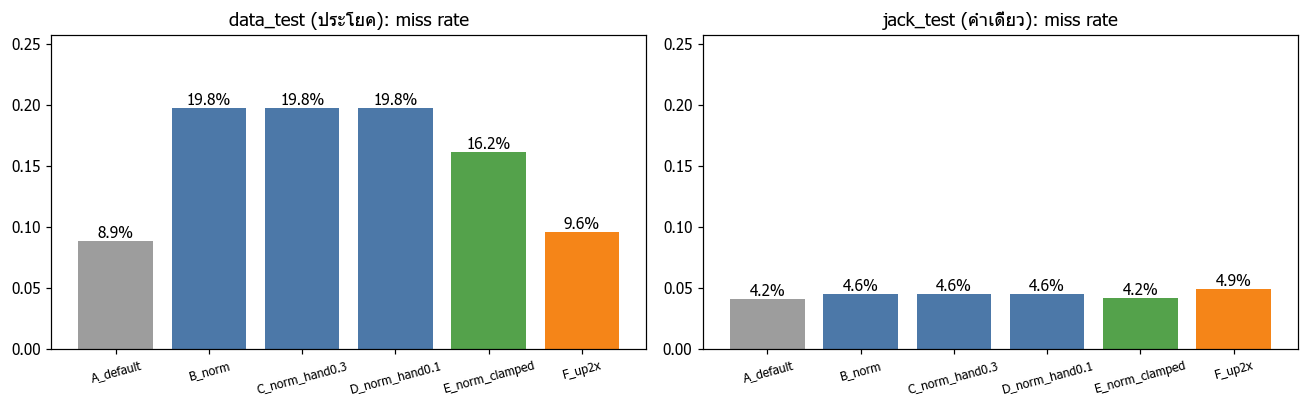

In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
for i, (g, sub) in enumerate(summ.groupby(level=0)):
    sub = sub.droplevel(0).reindex(SETTINGS)
    ax[i].bar(range(len(SETTINGS)), sub.miss_rate, color=['#9D9D9D', '#4C78A8', '#4C78A8', '#4C78A8', '#54A24B', '#F58518'])
    for j, v in enumerate(sub.miss_rate): ax[i].text(j, v, f'{v:.1%}', ha='center', va='bottom')
    ax[i].set_xticks(range(len(SETTINGS))); ax[i].set_xticklabels(SETTINGS, rotation=15, fontsize=8); ax[i].set_title(f'{g}: miss rate'); ax[i].set_ylim(0, max(summ.miss_rate) * 1.3)
plt.tight_layout(); plt.savefig(OUT / 'hand_miss_rate.png'); plt.show()

In [4]:
per_vid = H[H.group.str.startswith('data_test')].pivot_table(index='video', columns='setting', values=['missed', 'up'], aggfunc='sum')
mr = (per_vid['missed'] / per_vid['up'])[SETTINGS]
print('miss rate ต่อวิดีโอ (data_test ประโยค)'); mr.round(3)

miss rate ต่อวิดีโอ (data_test ประโยค)


setting,A_default,B_norm,C_norm_hand0.3,D_norm_hand0.1,E_norm_clamped,F_up2x
video,,,,,,
test1,0.060,0.077,0.077,0.077,0.070,0.070
ฉันปลอบเพื่อนร้องไห้,0.162,0.413,0.413,0.413,0.291,0.159
ฉันรักเพื่อน,0.142,0.132,0.132,0.132,0.137,0.156
พ่อดื่มน้ำ,0.025,0.086,0.086,0.086,0.086,0.040
ไปทานข้าวด้วยกันมั้ย,0.019,0.299,0.299,0.299,0.266,0.026


## 2. ภาพตัวอย่าง: ช่วงไหนที่มือหาย
แถบสีเทา = ข้อมือยกขึ้น (กำลังทำท่า), จุดสี = เฟรมที่หามือเจอ

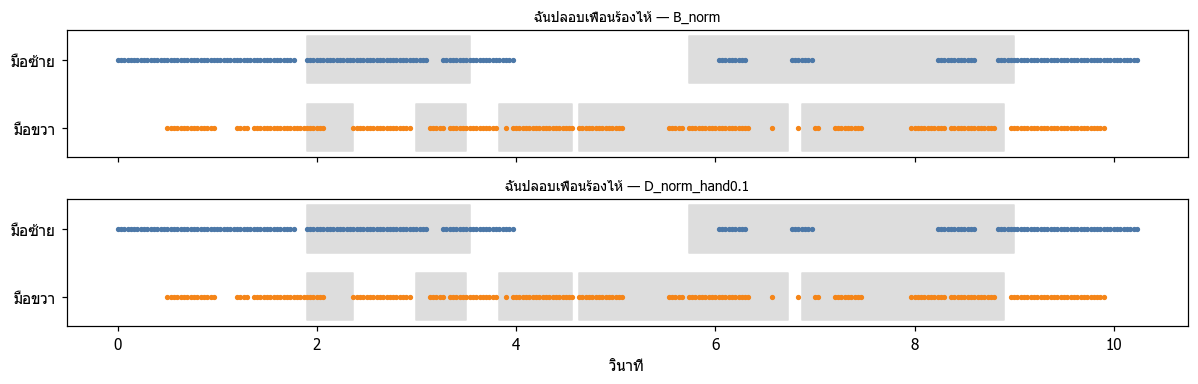

In [5]:
vid = mr[SETTINGS[1]].idxmax()
fig, axes = plt.subplots(2, 1, figsize=(11, 3.6), sharex=True)
for ax, s in zip(axes, ['B_norm', 'D_norm_hand0.1']):
    raw = load_raw(CACHE / s / f'{vid}.npz'); st = hand_stats(raw); t = raw['t']
    for k, (side, y) in enumerate((('L', 1), ('R', 0))):
        ax.fill_between(t, y - .35, y + .35, where=st[side]['up'], color='#ddd', step='mid')
        ax.scatter(t[st[side]['found']], np.full(st[side]['found'].sum(), y), s=6, c='#4C78A8' if side == 'L' else '#F58518')
    ax.set_yticks([0, 1]); ax.set_yticklabels(['มือขวา', 'มือซ้าย']); ax.set_title(f'{vid} — {s}', fontsize=9)
axes[-1].set_xlabel('วินาที'); plt.tight_layout(); plt.show()

## 2b. ทำไมการปรับแสงทำให้มือหาย
ซ้าย = ภาพจริง, ขวา = หลังปรับแสงแบบ browser (`ExposureNorm`) ผิวสว่างจนซีด มือกลืนกับหน้าและเสื้อ
สาเหตุ: วัดความสว่างจาก**ค่าเฉลี่ยทั้งภาพ** พื้นหลังเข้มทำให้คิดว่าภาพมืด จึงเร่ง gamma แรงมาก (0.47–0.58) ทั้งที่ตัวคนสว่างพออยู่แล้ว

ไปทานข้าวด้วยกันมั้ย: gamma=0.47 contrast=1.80
ฉันปลอบเพื่อนร้องไห้: gamma=0.57 contrast=0.92


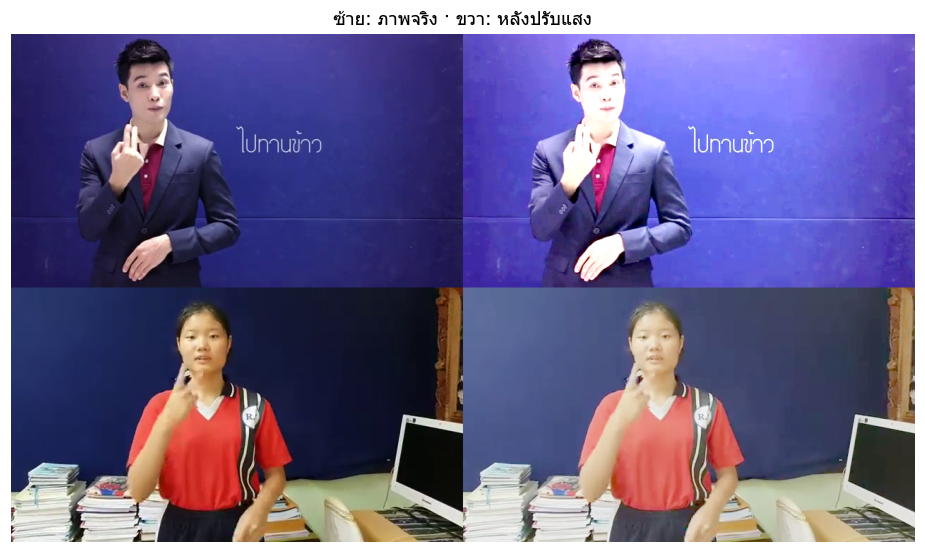

In [6]:
import cv2
from modules.mediapipe_pose import ExposureNorm
rows = []
for f, k in [('ไปทานข้าวด้วยกันมั้ย', 60), ('ฉันปลอบเพื่อนร้องไห้', 120)]:
    cap = cv2.VideoCapture(str(ROOT / 'data_test' / f'{f}.mp4')); n = ExposureNorm()
    for i in range(k + 1):
        ok, fr = cap.read(); out = n(cv2.cvtColor(fr, cv2.COLOR_BGR2RGB))
    rows.append(np.hstack([cv2.cvtColor(fr, cv2.COLOR_BGR2RGB), out]))
    print(f'{f}: gamma={n.g:.2f} contrast={n.c:.2f}')
plt.figure(figsize=(11, 6)); plt.imshow(np.vstack(rows)); plt.axis('off'); plt.title('ซ้าย: ภาพจริง · ขวา: หลังปรับแสง'); plt.show()

## 3. ผลการแปล (5 วิดีโอประโยค) แต่ละแบบ
ใช้ `SignPipeline` (ONNX, CPU, vocab = conversation) **ปิด LLM** (เครื่องนี้ไม่มี OPENAI key) และให้คะแนนด้วย `score_video` / `summarise` ของเพื่อน (`scripts/eval.py`)
แบบ A คือแบบเดียวกับที่เพื่อนใช้ใน `python main.py test`
⚠️ ตัวเลขของ A **ไม่ตรง**กับรายงานเพื่อน (`infer_v72.json`: 0.409 / 0.727) เพราะ `models/bank.npz` ใน repo ถูกแก้หลังรายงาน (รายงาน 19,680 คลิป, repo 19,656 คลิป: ลบคลิปของช่องที่หน้าคล้ายคนใน data_test ตาม README v7.2)
→ **baseline ของเรา = แบบ A ที่รันบนเครื่องนี้**

⚠️ data_test มีแค่ 22 คำ ทายถูกเพิ่ม 1 คำ = +0.045 ใช้ดูแนวโน้มเท่านั้น

In [7]:
import logging; logging.disable(logging.WARNING)
from modules.pipeline import SignPipeline
from modules.lexicon import DATA_TEST_REFS
import scripts.eval as ev
canon = ev._canon()
pipe = SignPipeline(backend='onnx', device='cpu', vocab='conversation', use_llm=False)
bank_vocab = {pipe.concepts[c] for c in pipe.bank.concepts_present}
E2E, DETAIL = {}, {}
for s in SETTINGS:
    vids = {}
    for stem, ref in DATA_TEST_REFS.items():
        r = pipe.run_landmarks(load_raw(CACHE / s / f'{stem}.npz'), out_dir=None, title=stem)
        vids[stem] = ev.score_video(r, ref, canon, bank_vocab)
    E2E[s] = ev.summarise(vids); DETAIL[s] = vids
cols = ['recall_top1', 'recall_top5', 'segments', 'count_abs_err', 'accepted', 'accepted_correct', 'mean_WER_top1']
e2e = pd.DataFrame(E2E).T[cols]
e2e.loc['เพื่อน v7.2 (มี LLM)'] = pd.Series(json.loads((ROOT / 'artifacts/reports/infer_v72.json').read_text(encoding='utf-8'))['results']['conversation']['summary'])[cols]
e2e.astype(float).round(3)

,recall_top1,recall_top5,segments,count_abs_err,accepted,accepted_correct,mean_WER_top1
A_default,0.500,0.727,23.0,1.0,3.0,3.0,0.758
B_norm,0.500,0.773,22.0,0.8,3.0,3.0,0.731
C_norm_hand0.3,0.500,0.773,22.0,0.8,3.0,3.0,0.731
D_norm_hand0.1,0.500,0.773,22.0,0.8,3.0,3.0,0.731
E_norm_clamped,0.455,0.773,22.0,0.8,2.0,2.0,0.781
F_up2x,0.500,0.773,24.0,1.2,2.0,2.0,0.848
เพื่อน v7.2 (มี LLM),0.409,0.727,23.0,1.0,3.0,3.0,0.874


In [8]:
rows = []
for s in SETTINGS:
    for stem, v in DETAIL[s].items():
        rows.append(dict(setting=s, video=stem, ref=' '.join(v['ref']), top1=' · '.join(v['top1']), R1=v['recall_top1'], R5=v['recall_top5']))
pd.DataFrame(rows).pivot_table(index='video', columns='setting', values='top1', aggfunc='first')[SETTINGS]

setting,A_default,B_norm,C_norm_hand0.3,D_norm_hand0.1,E_norm_clamped,F_up2x
video,,,,,,
test1,สวัสดี · สบายดี · ฉัน · ชอบ · หก · แมว · ข้าว ...,สวัสดี · สบายดี · ฉัน · ชอบ · หก · แมว · นั่ง ...,สวัสดี · สบายดี · ฉัน · ชอบ · หก · แมว · นั่ง ...,สวัสดี · สบายดี · ฉัน · ชอบ · หก · แมว · นั่ง ...,สวัสดี · สบายดี · ฉัน · ชอบ · หก · แมว · นั่ง ...,สวัสดี · สบายดี · ฉัน · ชอบ · หก · แมว · นั่ง ...
ฉันปลอบเพื่อนร้องไห้,ฉัน · เพื่อน · ดู · สงสาร,ฉัน · เพื่อน · ดู · แต่งงาน,ฉัน · เพื่อน · ดู · แต่งงาน,ฉัน · เพื่อน · ดู · แต่งงาน,เพื่อน · ดู · เกิด · กรุงเทพ,ฉัน · เพื่อน · ดู · เกิด · กรุงเทพ
ฉันรักเพื่อน,ฉัน · รัก,ฉัน · รัก,ฉัน · รัก,ฉัน · รัก,ฉัน · รัก,ฉัน · รัก
พ่อดื่มน้ำ,ศูนย์ · พ่อ · น้า · เกิด · ศูนย์,พ่อ · น้า · เกิด · ศูนย์,พ่อ · น้า · เกิด · ศูนย์,พ่อ · น้า · เกิด · ศูนย์,พ่อ · น้า · เกิด · ศูนย์,ศูนย์ · พ่อ · น้า · เกิด · ศูนย์
ไปทานข้าวด้วยกันมั้ย,คุณ · ฉัน · ข้าว · ไป,แฟน · ฉัน · กิน · ไป,แฟน · ฉัน · กิน · ไป,แฟน · ฉัน · กิน · ไป,คุณ · ฉัน · กิน · ไป,คุณ · ดู · กิน · ไป


## 3b. รอบ 3: วัดแสงจาก "ตัวคน" แทนทั้งภาพ + จำลองห้องมืด
- **G_person_norm** = ปรับแสงแบบเดิม แต่วัดความสว่างในกรอบรอบตัวคน (หน้า ไหล่ มือ จากเฟรมก่อนหน้า) แทนทั้งภาพ
- **\*_dark** = วิดีโอเดียวกันแต่ทำให้มืดลง (เหมือนห้องแสงน้อย) เพราะการปรับแสงมีไว้ช่วยกรณีนี้ ถ้าแก้แล้วห้องมืดแย่ลงก็ไม่คุ้ม

ใช้เฉพาะ 5 วิดีโอประโยค (สคริปต์: `pitty/scripts/hands_extract_r3.py`)

In [9]:
R3 = ['A_default', 'B_norm', 'G_person_norm', 'A_dark', 'B_dark', 'G_dark']
rows3 = []
for s in R3:
    up = miss = 0
    for stem in DATA_TEST_REFS:
        st = hand_stats(load_raw(CACHE / s / f'{stem}.npz'))
        up += sum(v['up'].sum() for v in st.values()); miss += sum((v['up'] & ~v['found']).sum() for v in st.values())
    vids = {stem: ev.score_video(pipe.run_landmarks(load_raw(CACHE / s / f'{stem}.npz'), out_dir=None, title=stem), ref, canon, bank_vocab)
            for stem, ref in DATA_TEST_REFS.items()}
    sm = ev.summarise(vids)
    rows3.append(dict(setting=s, light='มืด' if 'dark' in s else 'ปกติ', miss_rate=miss / up, recall_top1=sm['recall_top1'], recall_top5=sm['recall_top5'], mean_WER_top1=sm['mean_WER_top1']))
r3 = pd.DataFrame(rows3).set_index('setting'); r3.round(3)

,light,miss_rate,recall_top1,recall_top5,mean_WER_top1
setting,,,,,
A_default,ปกติ,0.089,0.500,0.727,0.758
B_norm,ปกติ,0.198,0.500,0.773,0.731
G_person_norm,ปกติ,0.144,0.500,0.773,0.848
A_dark,มืด,0.127,0.455,0.727,0.898
B_dark,มืด,0.161,0.455,0.636,0.779
G_dark,มืด,0.120,0.500,0.727,0.869


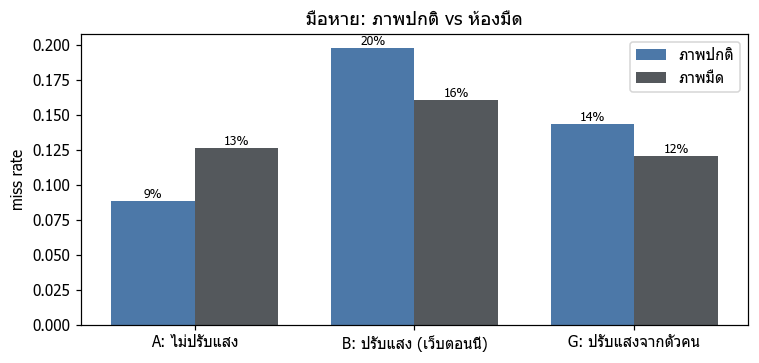

In [10]:
fig, ax = plt.subplots(figsize=(7, 3.4))
x = np.arange(3); w = .38
for k, (lab, col) in enumerate((('ปกติ', '#4C78A8'), ('มืด', '#54585C'))):
    sub = r3[r3.light == lab].miss_rate.values
    ax.bar(x + (k - .5) * w, sub, w, label=f'ภาพ{lab}', color=col)
    for i, v in enumerate(sub): ax.text(x[i] + (k - .5) * w, v, f'{v:.0%}', ha='center', va='bottom', fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(['A: ไม่ปรับแสง', 'B: ปรับแสง (เว็บตอนนี้)', 'G: ปรับแสงจากตัวคน']); ax.set_ylabel('miss rate'); ax.legend(); ax.set_title('มือหาย: ภาพปกติ vs ห้องมืด')
plt.tight_layout(); plt.savefig(OUT / 'hand_miss_dark.png'); plt.show()

## 4. สรุป

In [11]:
final = summ.xs('data_test (ประโยค)', level=0)[['miss_rate']].rename(columns={'miss_rate': 'miss_rate (ประโยค)'})
final['miss_rate (jack_test)'] = summ.xs('jack_test (คำเดี่ยว)', level=0)['miss_rate']
final = final.join(e2e[['recall_top1', 'recall_top5', 'mean_WER_top1']].astype(float))
final.reindex(SETTINGS).round(3)

,miss_rate (ประโยค),miss_rate (jack_test),recall_top1,recall_top5,mean_WER_top1
setting,,,,,
A_default,0.089,0.042,0.500,0.727,0.758
B_norm,0.198,0.046,0.500,0.773,0.731
C_norm_hand0.3,0.198,0.046,0.500,0.773,0.731
D_norm_hand0.1,0.198,0.046,0.500,0.773,0.731
E_norm_clamped,0.162,0.042,0.455,0.773,0.781
F_up2x,0.096,0.049,0.500,0.773,0.848


### ข้อสรุป Phase 1
| สิ่งที่ลอง | ผล |
|---|---|
| ลด threshold มือ 0.5 → 0.3 → 0.1 | **ไม่มีผลเลย** (ทุกเฟรมเหมือนเดิม) ไม่ใช่คอขวด |
| ปรับแสงแบบเดิม (B) | มือหาย **8.9% → 19.8%** (2.2 เท่า) ในภาพปกติ และ 12.7% → 16.1% ในห้องมืด **แย่ลงทั้งสองกรณี** |
| จำกัดความแรงการปรับแสง (E) | ดีกว่า B แต่ยังแย่กว่าไม่ปรับ (16.2%) |
| วัดแสงจากตัวคน (G) | ภาพปกติ 14.4% (แย่กว่าไม่ปรับ), ห้องมืด **12.0% ดีที่สุด** |
| ขยายภาพ 2 เท่า (F) | ไม่ต่างจากไม่ปรับ (9.6%) |
| ผลการแปล (22 คำ) | ทุกแบบต่างกันไม่เกิน 1–2 คำ → **วัดผลต่อการแปลไม่ได้ด้วยข้อมูลแค่นี้** |

**สาเหตุ:** การปรับแสงวัดความสว่างจากทั้งภาพ พื้นหลังเข้มทำให้คิดว่าภาพมืด จึงเร่งแสงจนผิวซีด มือกลืนกับหน้าและเสื้อ

**ข้อจำกัด**
- โค้ดเว็บ (`webapp/web/lib/holistic.ts: Normalizer`) จะปรับแสง**เฉพาะตอนภาพทั้งภาพมืด/สว่างเกิน** (mean < 0.3 หรือ > 0.72) และมี white balance ด้วย ส่วนที่ทดลองนี้ใช้ตัว Python (`ExposureNorm`) ที่ไม่มีเงื่อนไขนั้น
  ใน 5 วิดีโอนี้ เว็บจะปรับแสงกับ test1 (0.19), ไปทานข้าว (0.23) และอาจรวม ฉันปลอบ (0.30) ซึ่งเป็นวิดีโอที่มือหายเพิ่มมากที่สุด
- ห้องมืดเป็นการจำลอง และมีแค่ 5 วิดีโอ

**ข้อเสนอ (ยังไม่ได้แก้โค้ดเว็บ)**
1. **ทดสอบจริงได้ทันทีโดยไม่ต้องแก้โค้ด:** ในเว็บ **ปิดช่อง "ปรับภาพอัตโนมัติ"** แล้วดูว่ามือหลุดน้อยลงไหม
2. ถ้าใช่: เปลี่ยนค่าเริ่มต้นเป็นปิด (`SignStudio.tsx`: `useState(true)` → `false`) หรือเปลี่ยนไปวัดแสงจากกรอบตัวคน (แบบ G)